# 06.01 | Demographic associations with HRV

**Study:** Heart rate variability in older adults from southern Chile  
**Design:** One-factor-at-a-time, observational, descriptive and inferential analysis  
**Input:** `outputs/dataset_final.csv` — accepted 402-record analytical cohort  
**Questions:** (i) How do HRV distributions compare between women and men? (ii) How do seven cardiac measurements relate to continuous age? (iii) How do they compare across the **existing** age categories?

### Analytical commitments

- Retain the full accepted cohort. Do not remove, impute, winsorize, modify, or reclassify measurements.
- Five primary HRV responses: **SDNN, RMSSD, HF, LF, VLF**. Two complementary measures: **Mean RR, Mean HR**.
- **Continuous age:** Spearman's rank correlation, percentile-bootstrap 95% confidence interval, exact paired `n`, and an optional Kendall tau-b sensitivity estimate. Descriptive scatterplots with an optional LOWESS smoother (not an inferential model).
- **Sex:** complete distributional summaries; two-sided Mann–Whitney U; Cliff's delta with stratified bootstrap CI; differences in sample medians with bootstrap CI. Differences in medians are *descriptive location contrasts*, not what the Mann–Whitney test necessarily tests.
- **Age groups:** descriptive summaries; Kruskal–Wallis H with epsilon-squared effect estimate and stratified-bootstrap CI; transparent exploratory pairwise contrasts with Holm correction **within each outcome**, not gated on a significant omnibus test.
- **Multiple testing:** BH-FDR across 15 principal tests (5 primary outcomes × sex, continuous age, age groups). Separate BH-FDR across six complementary cardiac tests. Pairwise age-group tests are exploratory, corrected with Holm per outcome.
- **Plots:** native measurement units in all result tables; `log1p` **only for visualization** of HF/LF/VLF when appropriate and clearly labeled. Original input remains unchanged.
- No causal inference, prediction, automatically adjusted regressions, interaction analyses, or claims of clinical reference thresholds.

Each execution generates reproducible **CSV tables**, publication-quality **Seaborn/Matplotlib multipanel figures**, a figure manifest, a **methods README**, and an automatically generated **results report**. Generated outputs are written *outside* the notebook. All comments, charts, filenames, and documentation are in English.

## 0. Configuration and dependencies

Run this notebook from anywhere within the project tree, or specify an absolute path in `INPUT_FILE_OVERRIDE`. No connection to Google Drive is required for execution. Dependencies: `pandas`, `numpy`, `scipy`, `matplotlib`, `seaborn`, `IPython`; optional `statsmodels` for descriptive LOWESS. Bootstrap uses a fixed random seed.

In [25]:
from __future__ import annotations

import hashlib
import platform
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

# Input and outputs
INPUT_FILE_OVERRIDE = None  # e.g. "/absolute/project/path/outputs/dataset_final.csv"
OUTPUT_ROOT_OVERRIDE = None  # None -> <project>/eda_results/hrv_associations/06_01_demographic_associations

# Reproducible estimation
SEED = 20261128
N_BOOT = 1500  # Increase to 3000+ for a final-release precision check
CONFIDENCE_LEVEL = 0.95
ALPHA = 0.05
RUN_EXPLORATORY_AGE_PAIRS = True
RUN_KENDALL_SENSITIVITY = True

# Presentation
SHOW_FIGURES = True
PLOT_DPI = 230
VISUAL_LOG1P = {"t2m_pre_hf", "t2m_pre_lf", "t2m_pre_vlf"}  # visualization only
SHOW_DESCRIPTIVE_LOWESS = True  # if statsmodels is available

PRIMARY = {
    "t2m_pre_sdnn": "SDNN", "t2m_pre_rmssd": "RMSSD", "t2m_pre_hf": "HF",
    "t2m_pre_lf": "LF", "t2m_pre_vlf": "VLF",
}
COMPLEMENTARY = {"t2m_pre_mean_rr": "Mean RR", "t2m_pre_mean_hr": "Mean HR"}
MEASURES = {**PRIMARY, **COMPLEMENTARY}
SEX_ORDER = ["Female", "Male"]
AGE_GROUP_ORDER = ["60-69", "70-79", "80+"]
COLORS = {"Female": "#247E90", "Male": "#D58268",
          "60-69": "#247E90", "70-79": "#D6A052", "80+": "#8B74AB"}
NAVY, MUTED, ACCENT = "#19394C", "#627887", "#247E90"

sns.set_theme(style="whitegrid", context="notebook", palette="deep", font_scale=1.03)
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "#FFFFFF", "savefig.facecolor": "white",
    "axes.edgecolor": "#DCE5EB", "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#E7EDF1", "grid.alpha": 0.80,
    "axes.titleweight": "semibold", "axes.spines.top": False, "axes.spines.right": False,
    "figure.constrained_layout.use": False,
})
print("Python:", platform.python_version())
print("Packages:", {"pandas": pd.__version__, "numpy": np.__version__,
                   "scipy": getattr(stats, "__version__", "available"),
                   "matplotlib": matplotlib.__version__, "seaborn": sns.__version__})

Python: 3.14.10
Packages: {'pandas': '3.1.1', 'numpy': '2.5.5', 'scipy': 'available', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}


## 1. Input resolution and accepted dataset

Only the accepted analytical CSV is used. The recorded SHA-256 is checked for provenance, and the original source-row identifier, row count, labels and nonmissing measurements are validated. A different hash produces a **prominent warning**, whereas a different cohort size, missing values, unexpected categories, or duplicate source keys stop execution. Validation does not recode or remove data.

In [26]:
def find_project_input() -> Path:
    if INPUT_FILE_OVERRIDE is not None:
        f = Path(INPUT_FILE_OVERRIDE).expanduser().resolve()
        if not f.is_file():
            raise FileNotFoundError(f"INPUT_FILE_OVERRIDE does not exist: {f}")
        return f
    here = Path.cwd().resolve()
    for root in [here, *here.parents]:
        candidate = root / "outputs" / "dataset_final.csv"
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find outputs/dataset_final.csv in the current folder or a parent. "
        "Set INPUT_FILE_OVERRIDE in the configuration cell."
    )

input_file = find_project_input()
project_root = input_file.parent.parent if input_file.parent.name == "outputs" else input_file.parent
output_root = (Path(OUTPUT_ROOT_OVERRIDE).expanduser().resolve()
               if OUTPUT_ROOT_OVERRIDE else
               project_root / "eda_results" / "hrv_associations" / "06_01_demographic_associations")
tables_dir = output_root / "tables"
fig_dir = output_root / "figures" / "multipanels"
for target in [tables_dir, fig_dir]:
    target.mkdir(parents=True, exist_ok=True)

sha = hashlib.sha256(input_file.read_bytes()).hexdigest()
raw = pd.read_csv(input_file)
required = ["source_excel_row", "age", "sex_category", "age_group", *MEASURES]
missing_cols = [c for c in required if c not in raw.columns]
if missing_cols:
    raise ValueError(f"Required columns missing: {missing_cols}")
if raw["source_excel_row"].isna().any() or raw["source_excel_row"].duplicated().any():
    raise ValueError("Missing or duplicated source_excel_row. Inspect the input; do not silently drop records.")
if raw[required].isna().any().any():
    raise ValueError(f"Unexpected missing values in required columns: {raw[required].isna().sum().to_dict()}")

for col in ["age", *MEASURES]:
    if not pd.api.types.is_numeric_dtype(raw[col]):
        raise TypeError(f"{col} must be a numeric source column. No automatic recoding is performed.")
    if not np.isfinite(raw[col].to_numpy(dtype=float)).all():
        raise ValueError(f"Non-finite entries in {col}; check input provenance.")
if not (raw["age"] >= 60).all():
    raise ValueError("Age below 60 was observed, contradicting the finalized cohort.")

# Read-only convention: 'raw' is never assigned back or exported.
data = raw.copy(deep=True)
print("Input:", input_file)
print("SHA-256:", sha)
print("Verified records:", len(data), "| unique source_excel_row:", data.source_excel_row.nunique())
print("Output directory:", output_root)
print("Sex:", data.sex_category.value_counts().reindex(SEX_ORDER).to_dict())
print("Age groups:", data.age_group.value_counts().reindex(AGE_GROUP_ORDER).to_dict())

Input: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/outputs/dataset_final.csv
SHA-256: 687faa284c79bf4d1691d7e0a890274e255ad0bac3f9c47d337457694a794f38
Verified records: 402 | unique source_excel_row: 402
Output directory: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/hrv_associations/06_01_demographic_associations
Sex: {'Female': 294, 'Male': 108}
Age groups: {'60-69': 184, '70-79': 190, '80+': 28}


## 2. Shared estimators, uncertainty and export helpers

**Confidence intervals** use percentile bootstrap, with paired resampling for Spearman and within-category (stratified) resampling for group contrasts. All CIs describe uncertainty under the assumed independent-record sampling scheme. They do not address project-level heterogeneity or repeated measurements. Bootstrap samples are derived from the accepted cohort; no records are discarded from the original analysis.

In [27]:
def ci_bounds(values, level=CONFIDENCE_LEVEL):
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    if not len(v):
        return (np.nan, np.nan)
    tail = (1.0 - level) / 2.0
    return tuple(np.quantile(v, [tail, 1.0 - tail]).astype(float))


def boot_pair_spearman(x, y, rng, n_boot=N_BOOT):
    n = len(x)
    vals = np.empty(n_boot, dtype=float)
    for k in range(n_boot):
        ids = rng.integers(0, n, size=n)
        vals[k] = stats.spearmanr(x[ids], y[ids]).statistic
    return ci_bounds(vals)


def cliffs_delta(x, y):
    # Positive means observations in x tend to be greater than observations in y.
    a, b = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if not len(a) or not len(b):
        return np.nan
    u = stats.mannwhitneyu(a, b, alternative="two-sided", method="asymptotic").statistic
    return float(2.0 * u / (len(a) * len(b)) - 1.0)


def boot_two_group(x, y, rng, n_boot=N_BOOT):
    # Separate within-group resampling maintains observed groups and group sizes.
    a, b = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    deltas = np.empty(n_boot, dtype=float)
    median_differences = np.empty(n_boot, dtype=float)
    for k in range(n_boot):
        aa = a[rng.integers(0, len(a), len(a))]
        bb = b[rng.integers(0, len(b), len(b))]
        deltas[k] = cliffs_delta(aa, bb)
        median_differences[k] = float(np.median(aa) - np.median(bb))
    return (*ci_bounds(deltas), *ci_bounds(median_differences))


def kw_epsilon_squared(h, n, k):
    # Truncated at zero so small negative sampling estimates are not labeled a negative effect.
    return float(max(0.0, (h - k + 1.0) / (n - k))) if n > k else np.nan


def boot_kw_epsilon(groups, rng, n_boot=N_BOOT):
    vals = np.empty(n_boot, dtype=float)
    for k in range(n_boot):
        selected = [a[rng.integers(0, len(a), len(a))] for a in groups]
        h = stats.kruskal(*selected).statistic
        vals[k] = kw_epsilon_squared(h, sum(map(len, selected)), len(selected))
    return ci_bounds(vals)


def p_adjust_bh(pvals):
    p = np.asarray(pvals, dtype=float)
    q = np.full(len(p), np.nan)
    ok = np.flatnonzero(np.isfinite(p))
    if not len(ok):
        return q
    ranked = ok[np.argsort(p[ok])]
    m = len(ranked)
    adjusted = p[ranked] * m / np.arange(1, m + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    q[ranked] = np.minimum(adjusted, 1.0)
    return q


def p_adjust_holm(pvals):
    p = np.asarray(pvals, dtype=float)
    q = np.full(len(p), np.nan)
    ok = np.flatnonzero(np.isfinite(p))
    if not len(ok):
        return q
    ranked = ok[np.argsort(p[ok])]
    m = len(ranked)
    adjusted = np.maximum.accumulate(p[ranked] * (m - np.arange(m)))
    q[ranked] = np.minimum(adjusted, 1.0)
    return q


def summarize(arr):
    x = np.asarray(arr, dtype=float)
    q5, q25, q50, q75, q95 = np.quantile(x, [0.05, 0.25, 0.50, 0.75, 0.95])
    return {"n": len(x), "mean": float(np.mean(x)), "sd": float(np.std(x, ddof=1)),
            "median": float(q50), "q05": float(q5), "q25": float(q25),
            "q75": float(q75), "q95": float(q95), "iqr": float(q75-q25)}


def save_table(df, filename):
    path = tables_dir / filename
    df.to_csv(path, index=False, float_format="%.10g")
    return path


figure_manifest = []
def save_figure(fig, filename, description):
    path = fig_dir / filename
    fig.savefig(path, dpi=PLOT_DPI, bbox_inches="tight", pad_inches=0.18)
    figure_manifest.append({"figure": str(path.relative_to(output_root)), "description": description})
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)
    return path


def paint_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", color="#E5EDF2", alpha=0.85, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=9)


def figure_title(fig, main, subtitle=""):
    # Header positions use physical inches so the clearance is the same in
    # compact two-panel figures and taller multipanel sheets.
    height = fig.get_figheight()
    fig.suptitle(main, fontsize=18, color=NAVY, weight="bold",
                 x=0.035, ha="left", y=1 - 0.23 / height, va="top")
    if subtitle:
        fig.text(0.035, 1 - 0.75 / height, subtitle,
                 ha="left", va="top", fontsize=10, color=MUTED)


def figure_panel_top(fig):
    # Reserve 1.90 inches above all axes for the figure heading, subtitle,
    # and panel titles; they must never share the same vertical band.
    return 1 - 1.90 / fig.get_figheight()


def plot_values(frame, col):
    # Change only a visualization copy. Statistics use the original measurement units.
    values = frame[col].to_numpy(dtype=float)
    if col in VISUAL_LOG1P and np.all(values > -1):
        return np.log1p(values), f"log1p({MEASURES[col]}) — visualization only"
    return values, f"{MEASURES[col]} (source units)"

rng = np.random.default_rng(SEED)
print("Bootstrap replicates per CI:", N_BOOT)

Bootstrap replicates per CI: 1500


## 3. Complete demographic descriptive profiles

For each outcome, report the full-cohort reference distribution and separate profiles for **Female/Male** and **60–69/70–79/80+**. This section does not perform significance filtering and retains all original values. Interquartile ranges and 5th–95th percentiles preserve information about differences in spread and tails.

In [28]:
profile_rows = []
for outcome, label in MEASURES.items():
    profile_rows.append({"factor": "all", "category": "All", "outcome": outcome,
                         "outcome_label": label, **summarize(data[outcome].to_numpy())})
    for factor, levels in [("sex_category", SEX_ORDER), ("age_group", AGE_GROUP_ORDER)]:
        for category in levels:
            values = data.loc[data[factor] == category, outcome].to_numpy(dtype=float)
            profile_rows.append({"factor": factor, "category": category,
                                 "outcome": outcome, "outcome_label": label, **summarize(values)})
descriptive = pd.DataFrame(profile_rows)
save_table(descriptive, "demographic_hrv_descriptive_profiles.csv")
display(descriptive[["factor", "category", "outcome_label", "n", "median", "iqr", "q05", "q95"]].head(21))

,factor,category,outcome_label,n,median,iqr,q05,q95
0,all,All,SDNN,402,151.00,106.250,15.000,287.850
1,sex_category,Female,SDNN,294,162.50,96.750,57.550,300.800
2,sex_category,Male,SDNN,108,112.50,135.825,9.220,244.550
3,age_group,60-69,SDNN,184,151.50,111.250,12.190,270.850
4,age_group,70-79,SDNN,190,153.50,95.750,28.000,302.400
5,age_group,80+,SDNN,28,114.00,78.750,27.325,291.600
6,all,All,RMSSD,402,13.70,8.150,4.800,26.765
7,sex_category,Female,RMSSD,294,14.00,8.075,4.965,27.100
8,sex_category,Male,RMSSD,108,12.50,8.925,4.735,24.190
9,age_group,60-69,RMSSD,184,13.90,8.100,4.190,27.735


## 4. Continuous age versus each cardiac measure

Spearman's rho quantifies monotonic rank association, not the slope in original measurement units. The optional Kendall tau-b estimate is a sensitivity descriptor of ordinal concordance, especially appropriate because recorded ages are integer-valued (ties). Neither estimator can exclude a non-monotonic association when near zero.

In [29]:
age = data["age"].to_numpy(dtype=float)
continuous_rows, kendall_rows = [], []
for outcome, label in MEASURES.items():
    y = data[outcome].to_numpy(dtype=float)
    result = stats.spearmanr(age, y)
    low, high = boot_pair_spearman(age, y, rng)
    continuous_rows.append({"factor": "age", "outcome": outcome, "outcome_label": label,
                            "n": len(age), "spearman_rho": float(result.statistic),
                            "rho_ci_low": low, "rho_ci_high": high, "p_raw": float(result.pvalue)})
    if RUN_KENDALL_SENSITIVITY:
        tau = stats.kendalltau(age, y, variant="b")
        kendall_rows.append({"factor": "age", "outcome": outcome, "outcome_label": label,
                             "n": len(age), "kendall_tau_b": float(tau.statistic),
                             "kendall_p_raw": float(tau.pvalue)})
continuous = pd.DataFrame(continuous_rows)
kendall_sensitivity = pd.DataFrame(kendall_rows)
save_table(continuous, "age_continuous_spearman.csv")
if RUN_KENDALL_SENSITIVITY:
    save_table(kendall_sensitivity, "age_continuous_kendall_sensitivity.csv")
display(continuous.round(4))

,factor,outcome,outcome_label,n,spearman_rho,rho_ci_low,rho_ci_high,p_raw
0,age,t2m_pre_sdnn,SDNN,402,0.0224,-0.0802,0.1260,0.6546
1,age,t2m_pre_rmssd,RMSSD,402,0.0010,-0.0930,0.1013,0.9838
2,age,t2m_pre_hf,HF,402,-0.0946,-0.1882,0.0035,0.0581
3,age,t2m_pre_lf,LF,402,-0.0877,-0.1834,0.0129,0.0792
4,age,t2m_pre_vlf,VLF,402,-0.0710,-0.1674,0.0241,0.1553
5,age,t2m_pre_mean_rr,Mean RR,402,0.1598,0.0695,0.2497,0.0013
6,age,t2m_pre_mean_hr,Mean HR,402,-0.1589,-0.2538,-0.0650,0.0014


## 5. Sex-related distributional comparisons

The effect direction is always **Female − Male** for descriptive differences, and **Female versus Male** for Cliff's delta (positive indicates larger observed values among women). The two-sided Mann–Whitney U tests rank-distribution differences and does **not** automatically test equality of medians. Medians and percentile differences are independent descriptive summaries.

In [30]:
sex_rows = []
for outcome, label in MEASURES.items():
    female = data.loc[data.sex_category == "Female", outcome].to_numpy(dtype=float)
    male = data.loc[data.sex_category == "Male", outcome].to_numpy(dtype=float)
    test = stats.mannwhitneyu(female, male, alternative="two-sided", method="asymptotic")
    delta_ci_low, delta_ci_high, median_ci_low, median_ci_high = boot_two_group(female, male, rng)
    sex_rows.append({"factor": "sex_category", "outcome": outcome, "outcome_label": label,
                     "reference": "Male", "comparison": "Female",
                     "n_female": len(female), "n_male": len(male),
                     "median_female": float(np.median(female)), "median_male": float(np.median(male)),
                     "median_difference_female_minus_male": float(np.median(female) - np.median(male)),
                     "median_diff_ci_low": median_ci_low, "median_diff_ci_high": median_ci_high,
                     "cliffs_delta_female_vs_male": cliffs_delta(female, male),
                     "cliffs_ci_low": delta_ci_low, "cliffs_ci_high": delta_ci_high,
                     "mann_whitney_u": float(test.statistic), "p_raw": float(test.pvalue)})
sex_results = pd.DataFrame(sex_rows)
save_table(sex_results, "sex_comparisons.csv")
display(sex_results[["outcome_label", "n_female", "n_male", "median_female", "median_male",
                     "cliffs_delta_female_vs_male", "cliffs_ci_low", "cliffs_ci_high", "p_raw"]].round(4))

,outcome_label,n_female,n_male,median_female,median_male,cliffs_delta_female_vs_male,cliffs_ci_low,cliffs_ci_high,p_raw
0,SDNN,294,108,162.5,112.5,0.4067,0.2862,0.5246,0.0000
1,RMSSD,294,108,14.0,12.5,0.1674,0.0443,0.3005,0.0101
2,HF,294,108,116.0,72.0,0.1614,0.0284,0.2896,0.0131
3,LF,294,108,135.5,96.5,0.1903,0.0594,0.3141,0.0034
4,VLF,294,108,34.0,24.0,0.2392,0.1035,0.3601,0.0002
5,Mean RR,294,108,847.0,838.0,0.0236,-0.1081,0.1592,0.7176
6,Mean HR,294,108,71.0,71.5,-0.0209,-0.1487,0.1104,0.7484


## 6. Age-group differences and optional exploratory contrasts

The omnibus Kruskal–Wallis H test assesses rank-distribution differences across the three **unchanged** age groups. The reported epsilon-squared is an effect-size estimate, truncated at zero if its finite-sample formula yields a negative value. The percentile-bootstrap CI uses within-group resampling.

Pairwise age-group comparisons are **exploratory descriptions of specific group contrasts**. They are always exported when enabled and adjusted with Holm **within each outcome**. An omnibus p-value is not used as a gate, and small groups are not dropped or merged. Exact group sizes remain visible.

In [31]:
kw_rows, agepair_rows = [], []
for outcome, label in MEASURES.items():
    grouped = {group: data.loc[data.age_group == group, outcome].to_numpy(dtype=float)
               for group in AGE_GROUP_ORDER}
    groups = list(grouped.values())
    result = stats.kruskal(*groups)
    low, high = boot_kw_epsilon(groups, rng)
    kw_rows.append({"factor": "age_group", "outcome": outcome, "outcome_label": label,
                    "n": sum(map(len, groups)), "k": len(groups),
                    "group_sizes": " | ".join(f"{g}:{len(grouped[g])}" for g in AGE_GROUP_ORDER),
                    "kruskal_h": float(result.statistic), "epsilon_squared": kw_epsilon_squared(
                        result.statistic, sum(map(len, groups)), len(groups)),
                    "epsilon_ci_low": low, "epsilon_ci_high": high, "p_raw": float(result.pvalue)})
    if RUN_EXPLORATORY_AGE_PAIRS:
        for group_a, group_b in combinations(AGE_GROUP_ORDER, 2):
            a, b = grouped[group_a], grouped[group_b]
            mw = stats.mannwhitneyu(a, b, alternative="two-sided", method="asymptotic")
            d_low, d_high, med_low, med_high = boot_two_group(a, b, rng)
            agepair_rows.append({"factor": "age_group", "outcome": outcome,
                                 "outcome_label": label, "group_a": group_a, "group_b": group_b,
                                 "n_a": len(a), "n_b": len(b),
                                 "median_a": float(np.median(a)), "median_b": float(np.median(b)),
                                 "median_diff_a_minus_b": float(np.median(a) - np.median(b)),
                                 "median_diff_ci_low": med_low, "median_diff_ci_high": med_high,
                                 "cliffs_delta_a_vs_b": cliffs_delta(a, b),
                                 "cliffs_ci_low": d_low, "cliffs_ci_high": d_high,
                                 "mann_whitney_u": float(mw.statistic), "p_raw": float(mw.pvalue)})
kw_results = pd.DataFrame(kw_rows)
age_pairs = pd.DataFrame(agepair_rows)
if RUN_EXPLORATORY_AGE_PAIRS:
    age_pairs["p_holm_within_outcome"] = np.nan
    for outcome, idx in age_pairs.groupby("outcome", sort=False).groups.items():
        age_pairs.loc[idx, "p_holm_within_outcome"] = p_adjust_holm(age_pairs.loc[idx, "p_raw"])
    save_table(age_pairs, "age_group_pairwise_exploratory.csv")
save_table(kw_results, "age_group_kruskal_wallis.csv")
display(kw_results.round(4))

,factor,outcome,outcome_label,n,k,group_sizes,kruskal_h,epsilon_squared,epsilon_ci_low,epsilon_ci_high,p_raw
0,age_group,t2m_pre_sdnn,SDNN,402,3,60-69:184 | 70-79:190 | 80+:28,2.7337,0.0018,0.0,0.0302,0.2549
1,age_group,t2m_pre_rmssd,RMSSD,402,3,60-69:184 | 70-79:190 | 80+:28,1.0018,0.0000,0.0,0.0202,0.6060
2,age_group,t2m_pre_hf,HF,402,3,60-69:184 | 70-79:190 | 80+:28,5.0544,0.0077,0.0,0.0409,0.0799
3,age_group,t2m_pre_lf,LF,402,3,60-69:184 | 70-79:190 | 80+:28,8.3442,0.0159,0.0,0.0578,0.0154
4,age_group,t2m_pre_vlf,VLF,402,3,60-69:184 | 70-79:190 | 80+:28,5.8400,0.0096,0.0,0.0426,0.0539
5,age_group,t2m_pre_mean_rr,Mean RR,402,3,60-69:184 | 70-79:190 | 80+:28,8.7086,0.0168,0.0,0.0550,0.0129
6,age_group,t2m_pre_mean_hr,Mean HR,402,3,60-69:184 | 70-79:190 | 80+:28,8.6801,0.0167,0.0,0.0580,0.0130


## 7. Prespecified multiplicity bookkeeping

One **principal descriptive-inferential family** comprises five primary HRV outcomes × three unifactorial tests (continuous age, sex, age groups), = **15** tests. The six corresponding tests for Mean RR and Mean HR are a separately labeled **complementary family**. Benjamini–Hochberg adjusted values are transparently reported alongside *unadjusted p-values*, effect estimates, and CIs.

The age-continuous and age-category tests are related representations of the same attribute; their inclusion does not create independent biological evidence. A value of `q < 0.05` is not a physiological relevance threshold. The separate exploratory within-outcome age-group pair contrasts are recorded in their own table.

In [32]:
tests = []
for source, label in [(continuous, "age_continuous_spearman"),
                      (sex_results, "sex_mann_whitney"),
                      (kw_results, "age_group_kruskal_wallis")]:
    for _, row in source.iterrows():
        tests.append({"test": label, "outcome": row["outcome"], "outcome_label": row["outcome_label"],
                      "family": "primary_hrv" if row["outcome"] in PRIMARY else "complementary_cardiac",
                      "p_raw": row["p_raw"]})
multiplicity = pd.DataFrame(tests)
multiplicity["p_fdr_bh"] = np.nan
for family, idx in multiplicity.groupby("family", sort=False).groups.items():
    multiplicity.loc[idx, "p_fdr_bh"] = p_adjust_bh(multiplicity.loc[idx, "p_raw"])
save_table(multiplicity, "multiplicity_fdr_bh.csv")
assert multiplicity.groupby("family").size().to_dict() == {"complementary_cardiac": 6, "primary_hrv": 15}

def attach_q(df, test_name):
    lookup = multiplicity.loc[multiplicity.test == test_name, ["outcome", "family", "p_fdr_bh"]]
    return df.drop(columns=[c for c in ["family", "p_fdr_bh"] if c in df], errors="ignore").merge(
        lookup, on="outcome", how="left", validate="one_to_one")

continuous = attach_q(continuous, "age_continuous_spearman")
sex_results = attach_q(sex_results, "sex_mann_whitney")
kw_results = attach_q(kw_results, "age_group_kruskal_wallis")
save_table(continuous, "age_continuous_spearman.csv")
save_table(sex_results, "sex_comparisons.csv")
save_table(kw_results, "age_group_kruskal_wallis.csv")
display(multiplicity.round(5))

,test,outcome,outcome_label,family,p_raw,p_fdr_bh
0,age_continuous_spearman,t2m_pre_sdnn,SDNN,primary_hrv,0.65457,0.70133
1,age_continuous_spearman,t2m_pre_rmssd,RMSSD,primary_hrv,0.98375,0.98375
2,age_continuous_spearman,t2m_pre_hf,HF,primary_hrv,0.05805,0.10885
3,age_continuous_spearman,t2m_pre_lf,LF,primary_hrv,0.07918,0.11982
4,age_continuous_spearman,t2m_pre_vlf,VLF,primary_hrv,0.15528,0.21174
5,age_continuous_spearman,t2m_pre_mean_rr,Mean RR,complementary_cardiac,0.00130,0.00418
6,age_continuous_spearman,t2m_pre_mean_hr,Mean HR,complementary_cardiac,0.00139,0.00418
7,sex_mann_whitney,t2m_pre_sdnn,SDNN,primary_hrv,0.00000,0.00000
8,sex_mann_whitney,t2m_pre_rmssd,RMSSD,primary_hrv,0.01008,0.03780
9,sex_mann_whitney,t2m_pre_hf,HF,primary_hrv,0.01310,0.03855


## 8. Publication-oriented Seaborn visualizations

All figures are multipanels saved at high resolution, with a white editorial theme, consistent group colors, and clearly labeled visual-only transformations when used. Every figure is recreated from the accepted source values and **does not overwrite outputs from prior stages**. The first columns emphasize distributional profiles; ECDF panels reveal spread and tail differences more clearly than boxplots alone.

/tmp/ipykernel_43313/1536325175.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax_dist.set_xticklabels([f"{l}\n(n={(data[factor] == l).sum()})" for l in levels])
/tmp/ipykernel_43313/1536325175.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax_dist.set_xticklabels([f"{l}\n(n={(data[factor] == l).sum()})" for l in levels])
/tmp/ipykernel_43313/1536325175.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax_dist.set_xticklabels([f"{l}\n(n={(data[factor] == l).sum()})" for l in levels])
/tmp/ipykernel_43313/1536325175.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ti

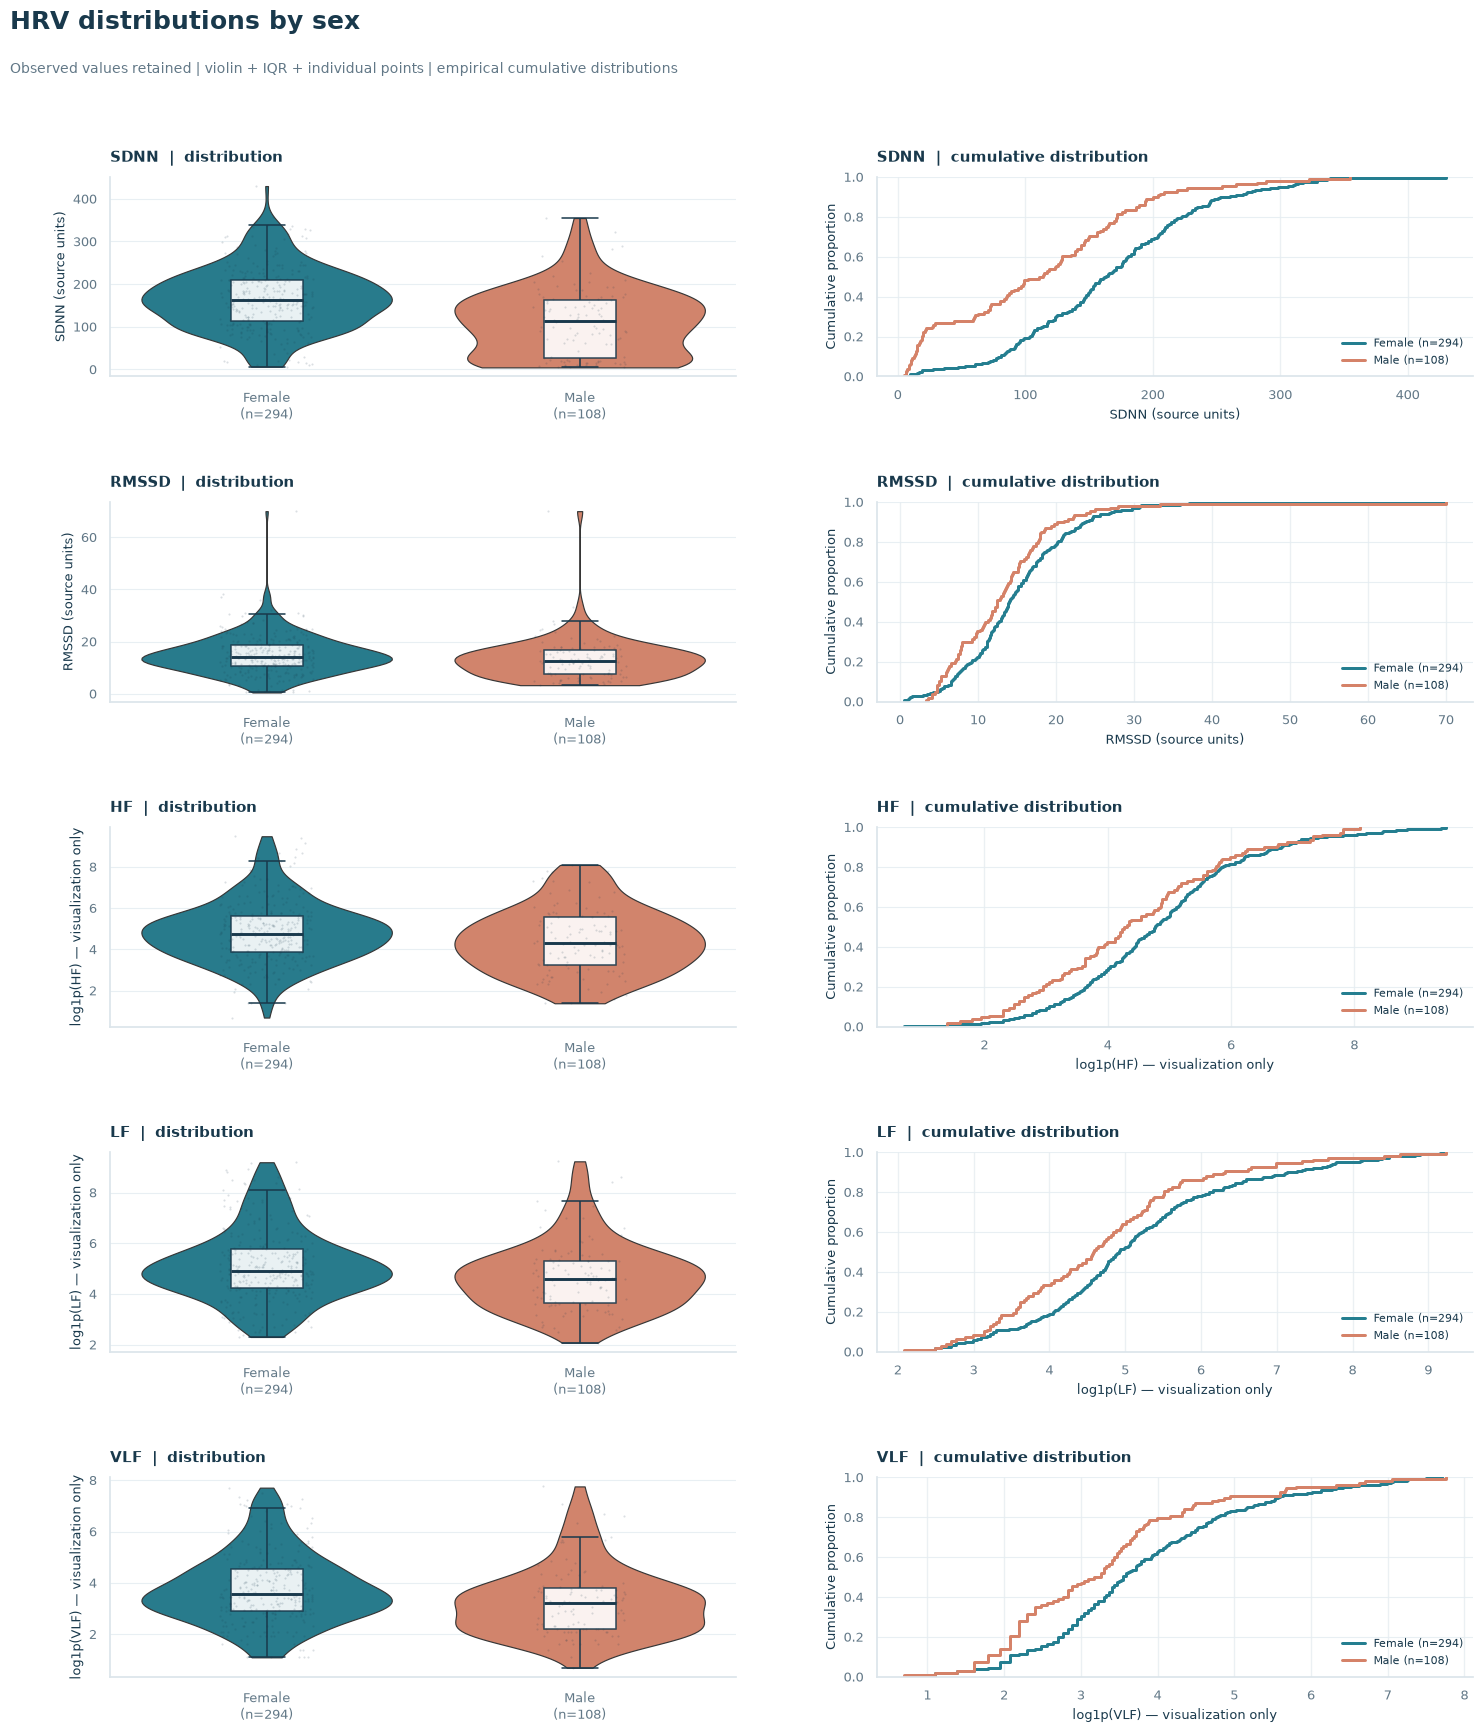

/tmp/ipykernel_43313/1536325175.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax_dist.set_xticklabels([f"{l}\n(n={(data[factor] == l).sum()})" for l in levels])
/tmp/ipykernel_43313/1536325175.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax_dist.set_xticklabels([f"{l}\n(n={(data[factor] == l).sum()})" for l in levels])


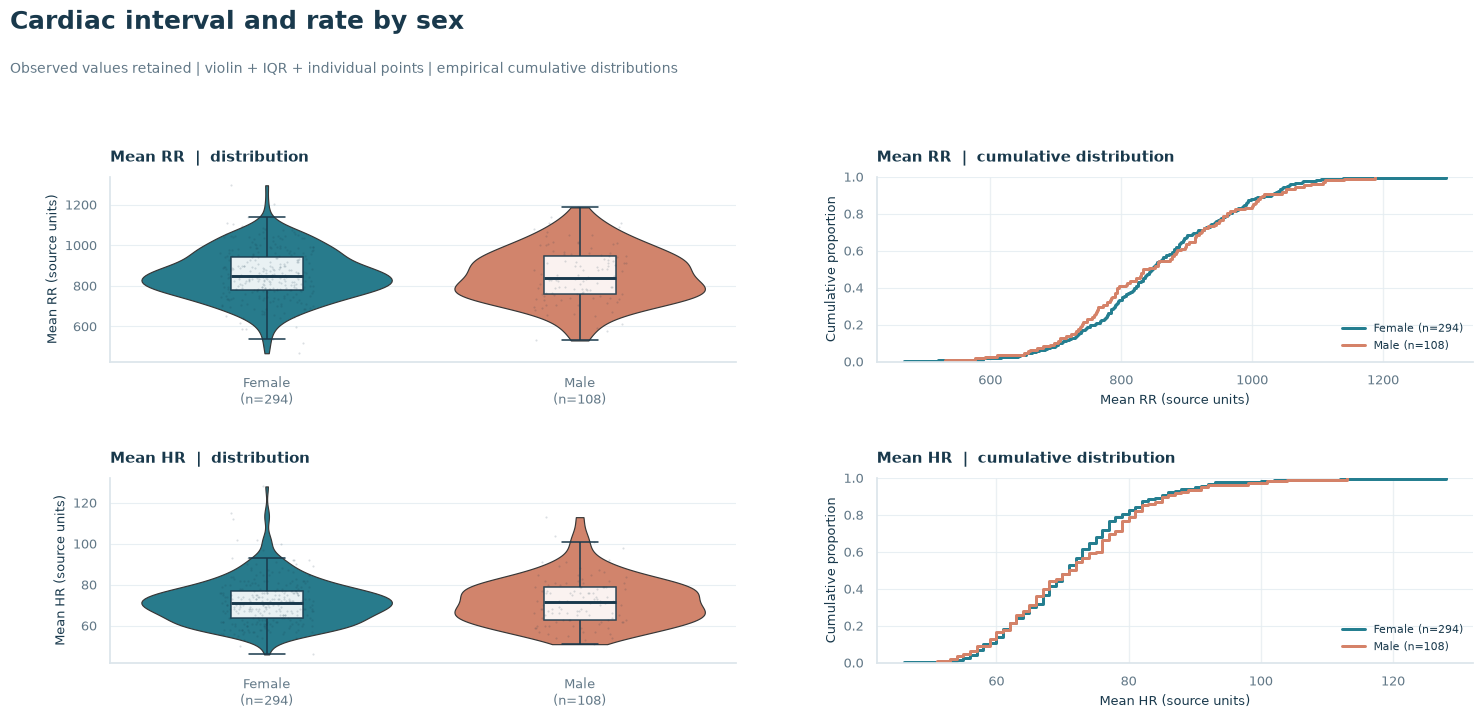

/tmp/ipykernel_43313/1536325175.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax_dist.set_xticklabels([f"{l}\n(n={(data[factor] == l).sum()})" for l in levels])
/tmp/ipykernel_43313/1536325175.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax_dist.set_xticklabels([f"{l}\n(n={(data[factor] == l).sum()})" for l in levels])
/tmp/ipykernel_43313/1536325175.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax_dist.set_xticklabels([f"{l}\n(n={(data[factor] == l).sum()})" for l in levels])
/tmp/ipykernel_43313/1536325175.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ti

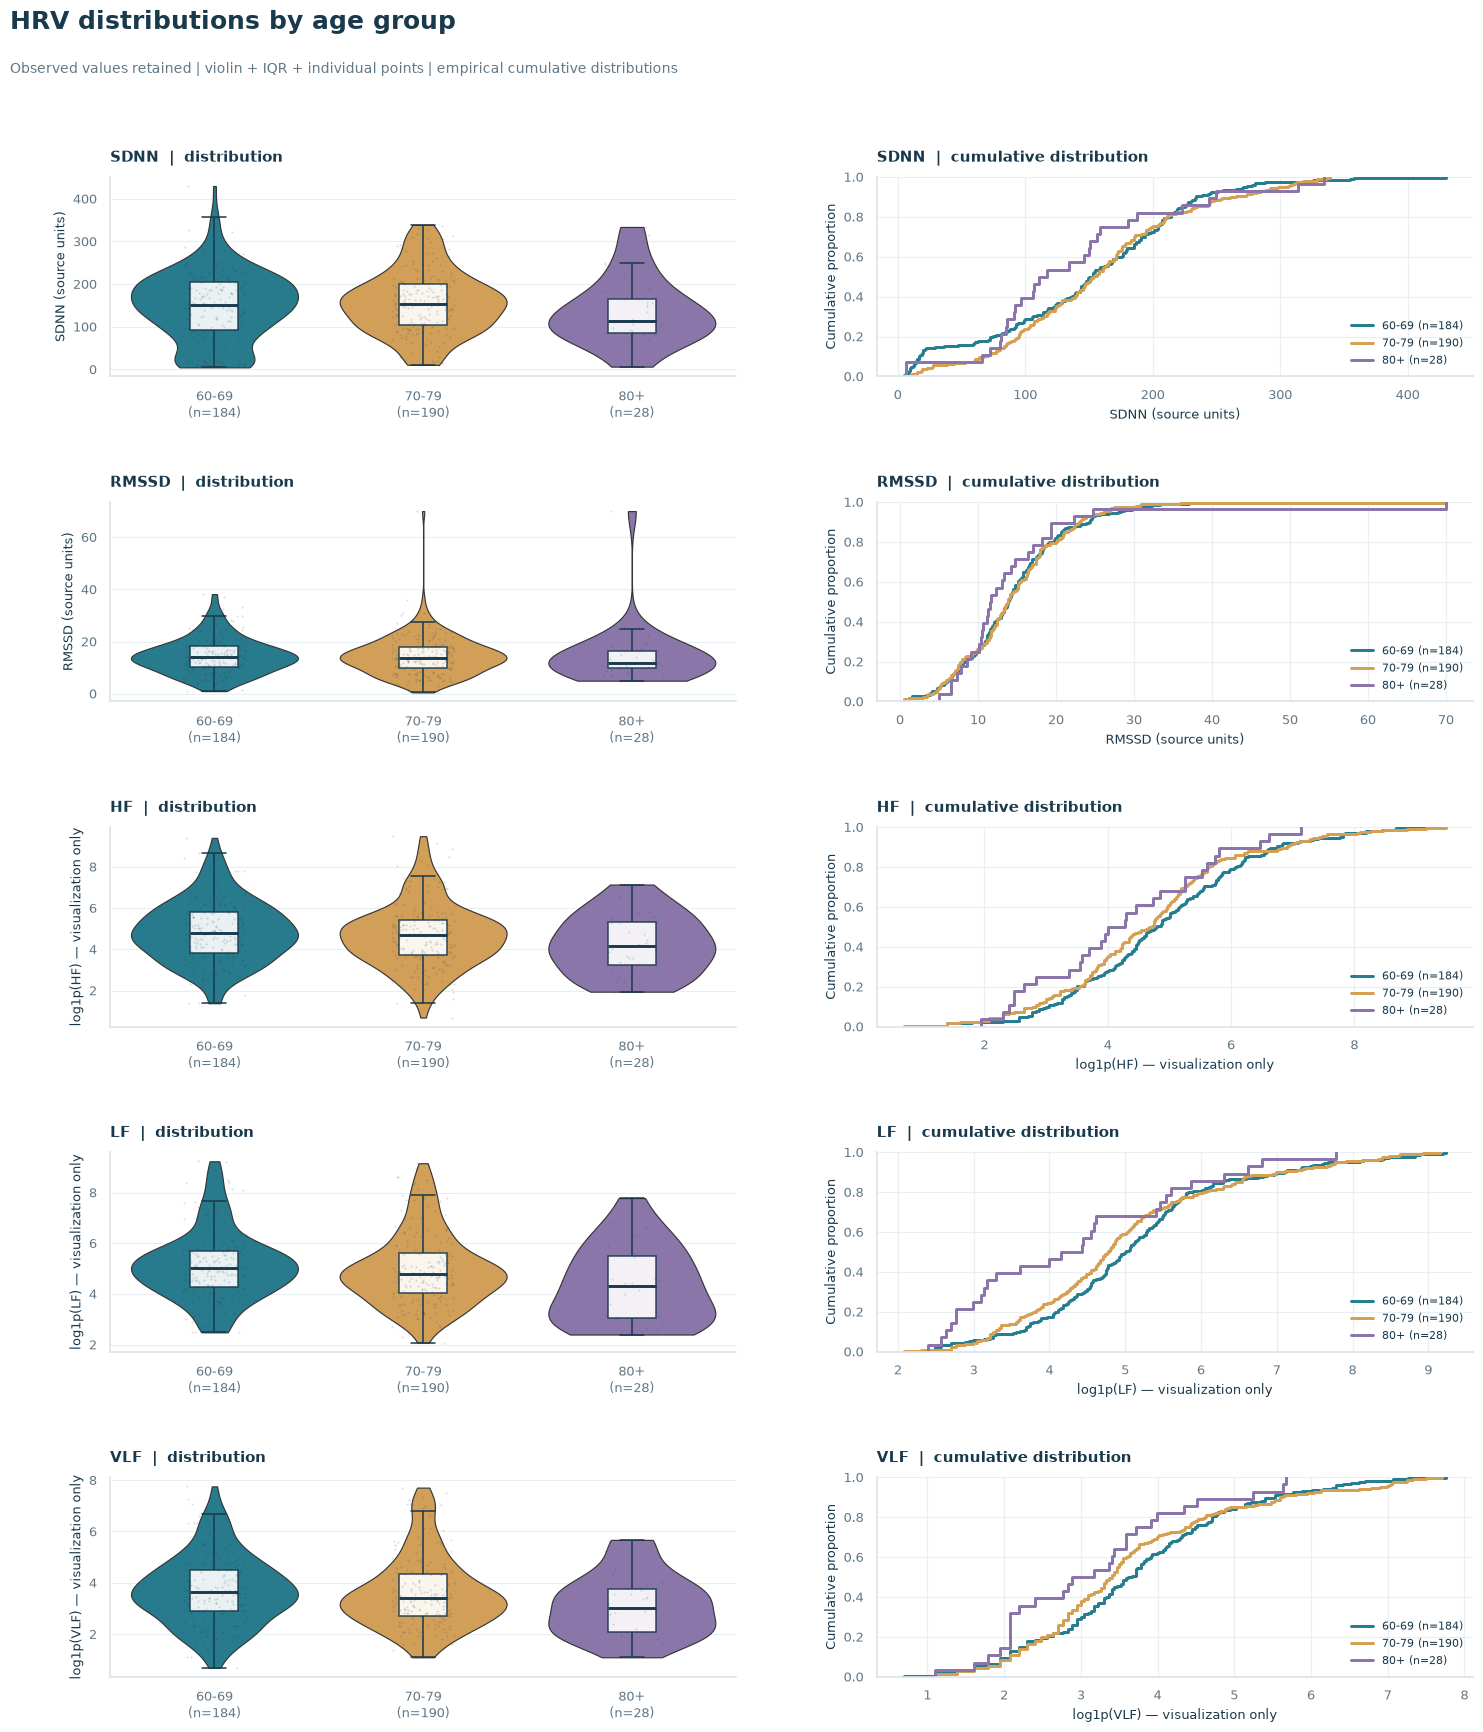

/tmp/ipykernel_43313/1536325175.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax_dist.set_xticklabels([f"{l}\n(n={(data[factor] == l).sum()})" for l in levels])
/tmp/ipykernel_43313/1536325175.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax_dist.set_xticklabels([f"{l}\n(n={(data[factor] == l).sum()})" for l in levels])


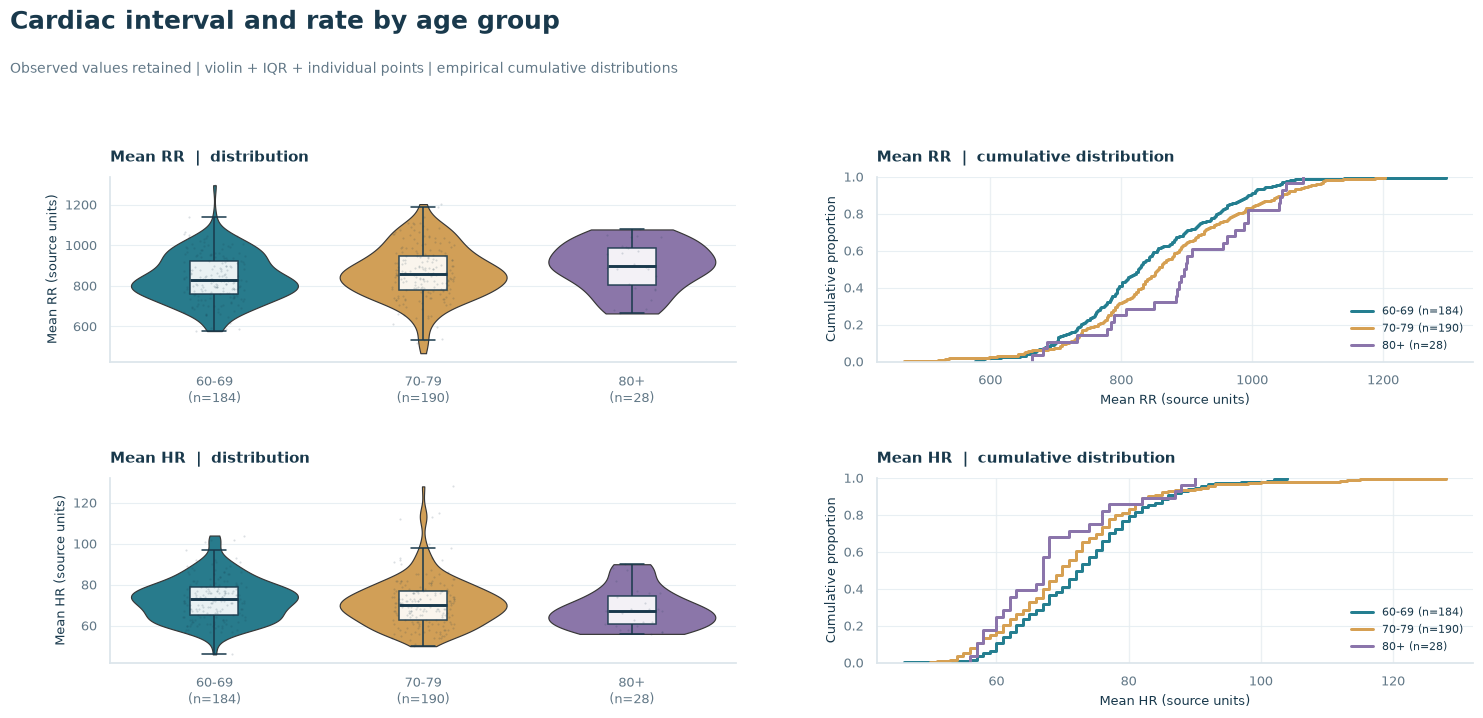

PosixPath('/home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/hrv_associations/06_01_demographic_associations/figures/multipanels/04_agegroup_complementary_cardiac_profiles.png')

In [33]:
def distribution_sheet(factor, subset, filename, heading):
    levels = SEX_ORDER if factor == "sex_category" else AGE_GROUP_ORDER
    chosen = [k for k in MEASURES if (k in PRIMARY) == (subset == "primary")]
    fig, axes = plt.subplots(len(chosen), 2, figsize=(15.4, 3.55 * len(chosen)),
                             gridspec_kw={"width_ratios": [1.05, 1.0]})
    axes = np.asarray(axes).reshape(len(chosen), 2)
    for i, outcome in enumerate(chosen):
        ax_dist, ax_cdf = axes[i]
        vals, scale_label = plot_values(data, outcome)
        frame = pd.DataFrame({"category": data[factor].to_numpy(), "value": vals})
        # KDE-free violin/box/points. Extreme tails remain included on the visible axis.
        try:
            sns.violinplot(data=frame, x="category", y="value", order=levels,
                           hue="category", hue_order=levels, palette=COLORS,
                           legend=False, density_norm="width", cut=0, inner=None,
                           linewidth=0.85, saturation=0.92, ax=ax_dist)
        except TypeError:
            sns.violinplot(data=frame, x="category", y="value", order=levels,
                           palette=[COLORS[x] for x in levels], cut=0, inner=None,
                           linewidth=0.85, ax=ax_dist)
        sns.boxplot(data=frame, x="category", y="value", order=levels, width=0.23,
                    showfliers=False, color="white", linewidth=1.1,
                    boxprops={"edgecolor": NAVY, "facecolor": "white", "alpha": 0.9},
                    medianprops={"color": NAVY, "linewidth": 2.1},
                    whiskerprops={"color": NAVY}, capprops={"color": NAVY}, ax=ax_dist)
        sns.stripplot(data=frame, x="category", y="value", order=levels,
                      color=NAVY, size=1.5, alpha=0.16, jitter=0.15, ax=ax_dist)
        ax_dist.set_xlabel("")
        ax_dist.set_ylabel(scale_label, fontsize=9)
        ax_dist.set_title(f"{MEASURES[outcome]}  |  distribution", loc="left", fontsize=11, pad=11)
        ax_dist.set_xticklabels([f"{l}\n(n={(data[factor] == l).sum()})" for l in levels])
        for level in levels:
            one = frame.loc[frame.category == level, "value"]
            sns.ecdfplot(x=one, ax=ax_cdf, label=f"{level} (n={len(one)})",
                         color=COLORS[level], linewidth=2.15)
        ax_cdf.set_xlabel(scale_label, fontsize=9)
        ax_cdf.set_ylabel("Cumulative proportion", fontsize=9)
        ax_cdf.set_title(f"{MEASURES[outcome]}  |  cumulative distribution", loc="left", fontsize=11, pad=11)
        ax_cdf.legend(frameon=False, loc="lower right", fontsize=8)
        for ax in [ax_dist, ax_cdf]:
            paint_axis(ax)
    fig.subplots_adjust(left=0.10, right=0.985, top=figure_panel_top(fig), bottom=0.048, wspace=0.23, hspace=0.63)
    figure_title(fig, heading, "Observed values retained | violin + IQR + individual points | empirical cumulative distributions")
    return save_figure(fig, filename, f"{heading}: distributions and ECDF across {factor}")

# Demographic category profiles: five primary outcomes and two complementary cardiac outcomes.
distribution_sheet("sex_category", "primary", "01_sex_primary_hrv_profiles.png", "HRV distributions by sex")
distribution_sheet("sex_category", "complementary", "02_sex_complementary_cardiac_profiles.png", "Cardiac interval and rate by sex")
distribution_sheet("age_group", "primary", "03_agegroup_primary_hrv_profiles.png", "HRV distributions by age group")
distribution_sheet("age_group", "complementary", "04_agegroup_complementary_cardiac_profiles.png", "Cardiac interval and rate by age group")

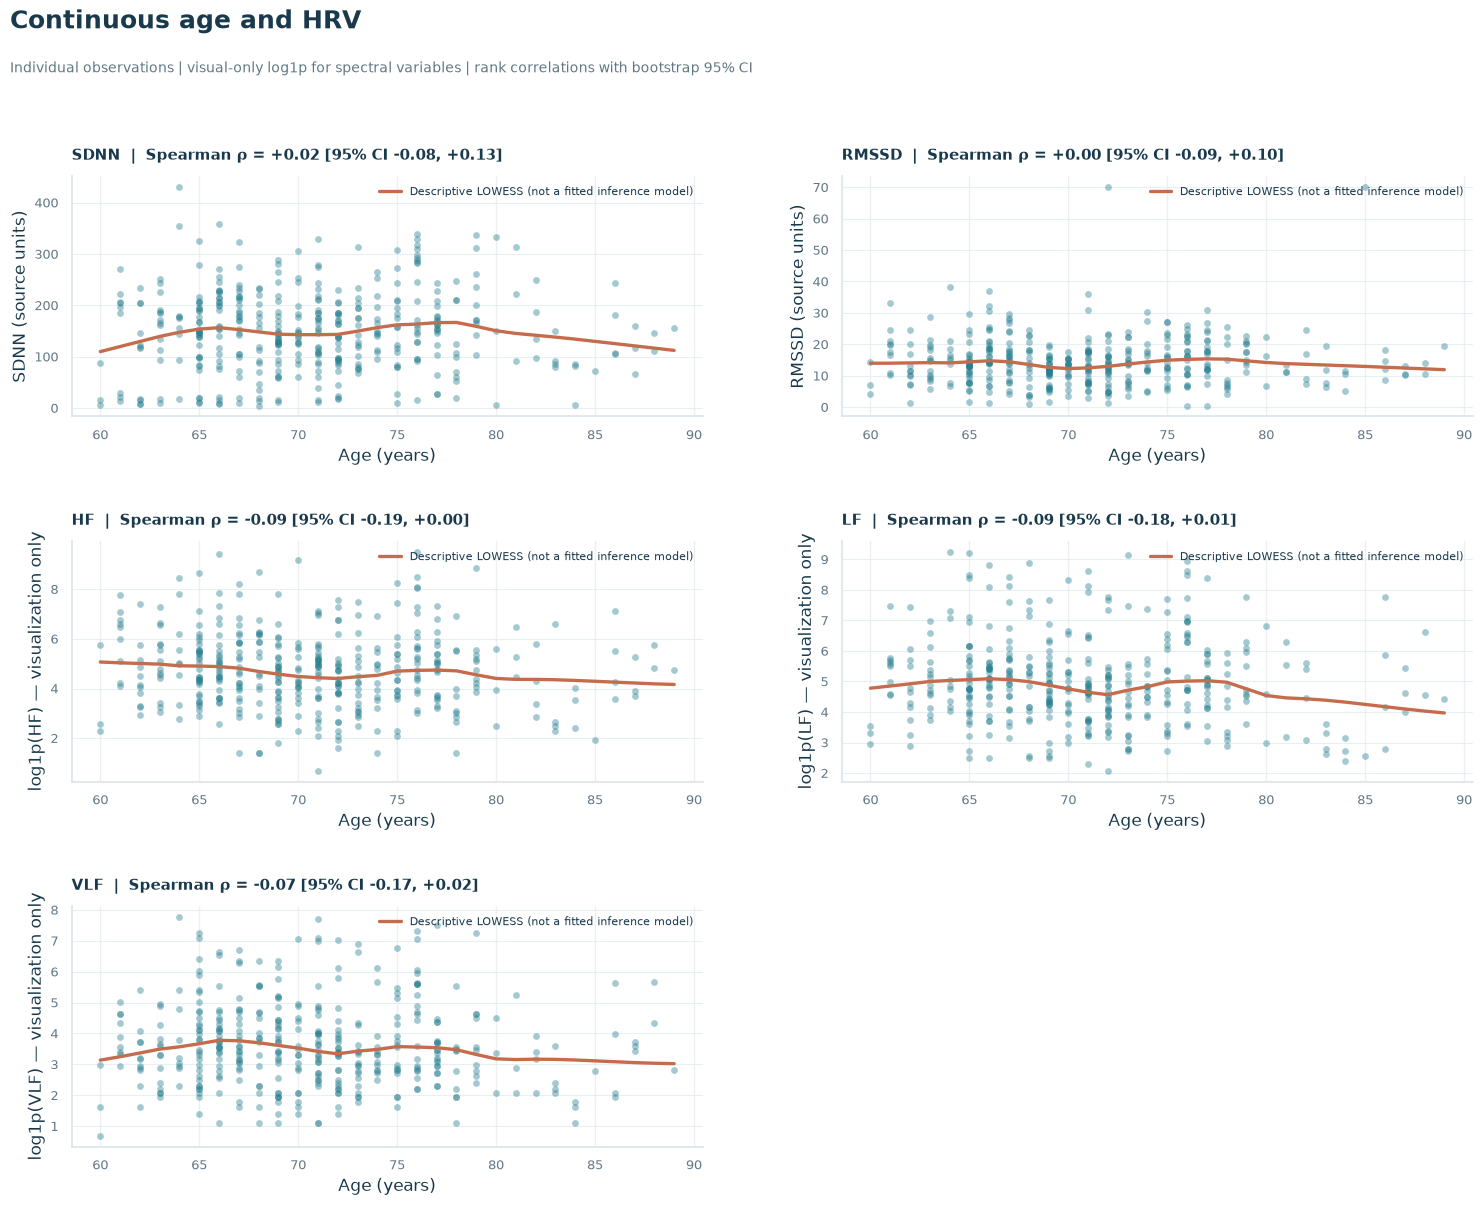

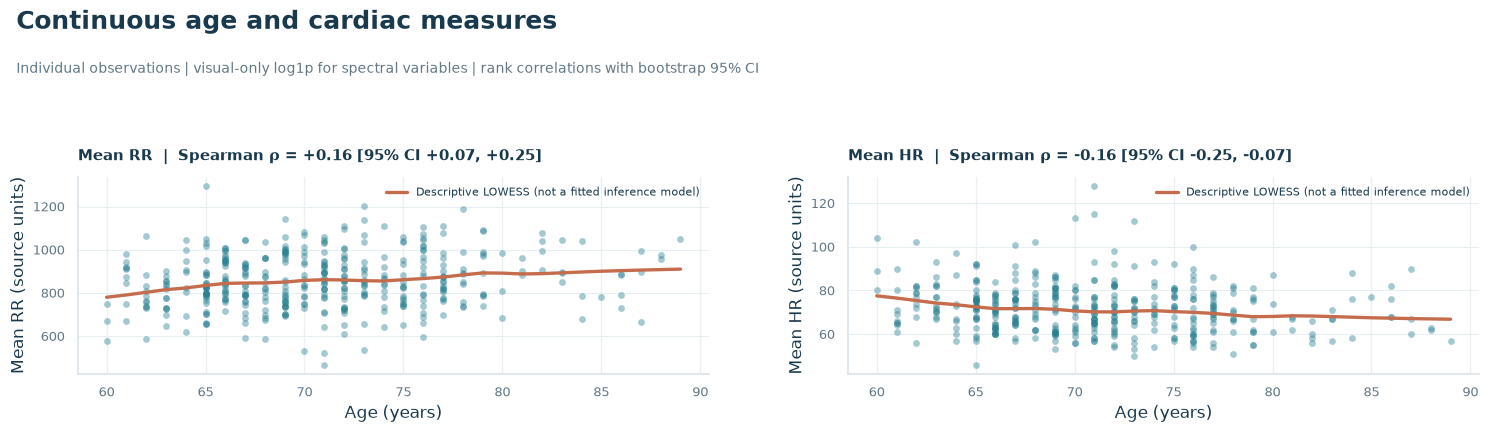

PosixPath('/home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/hrv_associations/06_01_demographic_associations/figures/multipanels/06_age_continuous_complementary_scatter.png')

In [34]:
try:
    from statsmodels.nonparametric.smoothers_lowess import lowess
    LOWESS_AVAILABLE = SHOW_DESCRIPTIVE_LOWESS
except ImportError:
    LOWESS_AVAILABLE = False
    print("statsmodels not installed; age scatterplots will omit the optional LOWESS descriptive curve.")


def continuous_scatter_sheet(subset, filename, heading):
    chosen = [k for k in MEASURES if (k in PRIMARY) == (subset == "primary")]
    n_cols = 2
    n_rows = int(np.ceil(len(chosen) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15.4, 4.25 * n_rows))
    axes = np.asarray(axes).reshape(-1)
    rho_idx = continuous.set_index("outcome")
    for ax, outcome in zip(axes, chosen):
        values, scale_label = plot_values(data, outcome)
        scatter = pd.DataFrame({"age": age, "value": values})
        sns.scatterplot(data=scatter, x="age", y="value", color="#277F91",
                        alpha=0.42, s=24, linewidth=0, ax=ax)
        if LOWESS_AVAILABLE:
            trend = lowess(values, age, frac=0.38, it=1, return_sorted=True)
            ax.plot(trend[:, 0], trend[:, 1], color="#C56C4D", lw=2.4,
                    label="Descriptive LOWESS (not a fitted inference model)")
        point = rho_idx.loc[outcome]
        ax.set_title(f"{MEASURES[outcome]}  |  Spearman ρ = {point.spearman_rho:+.2f} "
                     f"[95% CI {point.rho_ci_low:+.2f}, {point.rho_ci_high:+.2f}]",
                     fontsize=10.6, loc="left", pad=12)
        ax.set_xlabel("Age (years)")
        ax.set_ylabel(scale_label)
        if LOWESS_AVAILABLE:
            ax.legend(frameon=False, loc="upper right", fontsize=7.8)
        paint_axis(ax)
    for ax in axes[len(chosen):]:
        ax.axis("off")
    fig.subplots_adjust(left=0.075, right=0.985, top=figure_panel_top(fig), bottom=0.09, wspace=0.22, hspace=0.52)
    figure_title(fig, heading, "Individual observations | visual-only log1p for spectral variables | rank correlations with bootstrap 95% CI")
    return save_figure(fig, filename, f"{heading}: scatterplots, confidence intervals, descriptive LOWESS if available")

continuous_scatter_sheet("primary", "05_age_continuous_primary_scatter.png", "Continuous age and HRV")
continuous_scatter_sheet("complementary", "06_age_continuous_complementary_scatter.png", "Continuous age and cardiac measures")

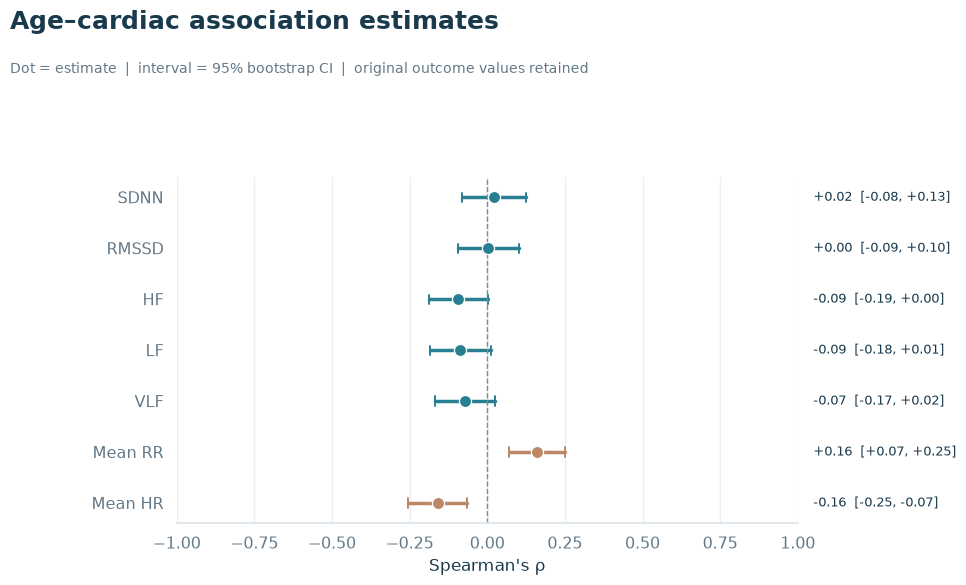

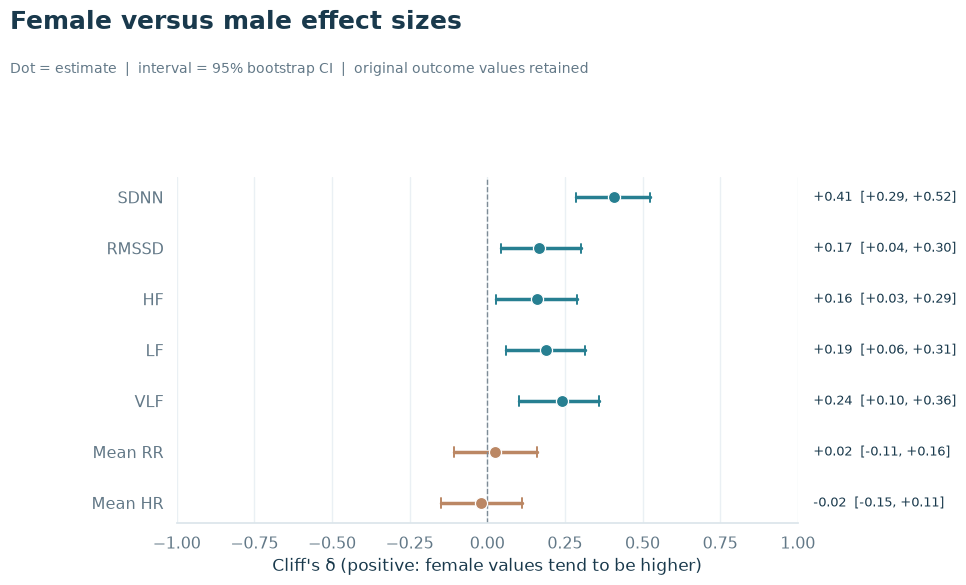

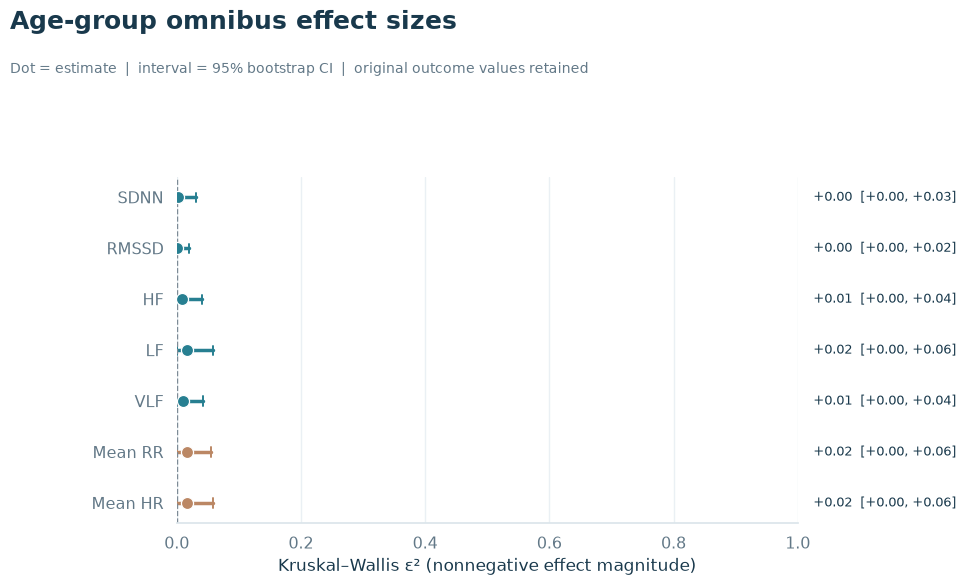

PosixPath('/home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/hrv_associations/06_01_demographic_associations/figures/multipanels/09_agegroup_epsilon_forest.png')

In [35]:
def forest_plot(frame, xcol, lo, hi, filename, heading, xlabel, low=-1.0, high=1.0, baseline=0.0):
    ordered = frame.copy().reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(11.5, max(4.5, 0.63 * len(ordered) + 1.9)))
    ypos = np.arange(len(ordered))[::-1]
    vals = ordered[xcol].astype(float).to_numpy()
    lower = ordered[lo].astype(float).to_numpy()
    upper = ordered[hi].astype(float).to_numpy()
    color = ["#277F91" if out in PRIMARY else "#BB8764" for out in ordered.outcome]
    for i, y in enumerate(ypos):
        ax.plot([lower[i], upper[i]], [y, y], color=color[i], lw=2.5, solid_capstyle="round")
        ax.plot([lower[i], lower[i]], [y-0.09, y+0.09], color=color[i], lw=1.4)
        ax.plot([upper[i], upper[i]], [y-0.09, y+0.09], color=color[i], lw=1.4)
        ax.scatter(vals[i], y, s=76, color=color[i], edgecolors="white", linewidth=0.9, zorder=3)
        ax.text(1.025, y,
                f"{vals[i]:+.2f}  [{lower[i]:+.2f}, {upper[i]:+.2f}]",
                transform=ax.get_yaxis_transform(), clip_on=False, va="center", fontsize=9, color=NAVY)
    ax.axvline(baseline, color="#7D8B96", ls="--", lw=1)
    ax.set_yticks(ypos, ordered.outcome_label)
    ax.set_xlim(low, high)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#E5EDF2")
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    fig.subplots_adjust(left=0.18, right=0.72, top=figure_panel_top(fig), bottom=0.15)
    figure_title(fig, heading, "Dot = estimate  |  interval = 95% bootstrap CI  |  original outcome values retained")
    return save_figure(fig, filename, f"{heading}: effect estimates and bootstrap uncertainty")

forest_plot(continuous, "spearman_rho", "rho_ci_low", "rho_ci_high",
            "07_age_spearman_forest.png", "Age–cardiac association estimates",
            "Spearman's ρ", low=-1, high=1)
forest_plot(sex_results, "cliffs_delta_female_vs_male", "cliffs_ci_low", "cliffs_ci_high",
            "08_sex_cliffs_delta_forest.png", "Female versus male effect sizes",
            "Cliff's δ (positive: female values tend to be higher)", low=-1, high=1)
forest_plot(kw_results, "epsilon_squared", "epsilon_ci_low", "epsilon_ci_high",
            "09_agegroup_epsilon_forest.png", "Age-group omnibus effect sizes",
            "Kruskal–Wallis ε² (nonnegative effect magnitude)", low=0, high=1, baseline=0)

## 9. Save output manifest, provenance, method documentation and results report

`README_06_01_demographic_associations.md` records all estimators, parameter values, output paths, and limitations. `06_01_demographic_associations_results.md` is **generated from these results** and includes non-significant estimates; it does not invent or select patterns by significance. These files are created on execution and are not part of the notebook delivery archive.

In [36]:
save_table(pd.DataFrame(figure_manifest), "figure_manifest.csv")
provenance = pd.DataFrame([{
    "source_file": str(input_file), "source_sha256": sha,
    "n_records": len(data), "source_id": "source_excel_row", "n_unique_source_ids": data.source_excel_row.nunique(),
    "bootstrap_replicates": N_BOOT, "seed": SEED, "confidence_level": CONFIDENCE_LEVEL,
    "primary_outcomes": " | ".join(PRIMARY), "complementary_outcomes": " | ".join(COMPLEMENTARY),
    "visual_log1p_only": " | ".join(sorted(VISUAL_LOG1P)),
    "scipy_version": __import__("scipy").__version__, "pandas_version": pd.__version__,
    "numpy_version": np.__version__, "seaborn_version": sns.__version__,
    "matplotlib_version": matplotlib.__version__, "python_version": platform.python_version(),
}])
save_table(provenance, "run_provenance.csv")


def format_report_value(value, column, digits=3):
    if pd.isna(value):
        return "NA"
    if column in {"p_raw", "p_fdr_bh", "p_holm_within_outcome", "kendall_p_raw"} and float(value) < 0.001:
        return ("q < 0.001" if column in {"p_fdr_bh", "p_holm_within_outcome"} else "p < 0.001")
    if isinstance(value, (int, float, np.number)):
        return f"{value:.{digits}f}"
    return str(value)

def markdown_table(frame, columns, digits=3):
    out = frame.loc[:, columns].copy()
    for col in out.select_dtypes(include="number").columns:
        out[col] = out[col].map(lambda v: format_report_value(v, col, digits))
    # pandas' tabular display is readable and avoids requiring the optional 'tabulate' package.
    widths = {col: max(len(col), *(len(str(x)) for x in out[col].tolist())) for col in columns}
    header = "| " + " | ".join(col.ljust(widths[col]) for col in columns) + " |"
    separator = "| " + " | ".join("-" * widths[col] for col in columns) + " |"
    lines = ["| " + " | ".join(str(row[col]).ljust(widths[col]) for col in columns) + " |"
             for _, row in out.iterrows()]
    return "\n".join([header, separator, *lines])

readme = f"""# 06.01 Demographic associations with HRV

## Scope and input
- Accepted dataset: `outputs/dataset_final.csv`; {len(data)} records.
- Immutable source identifier: `source_excel_row`. All identifiers unique.
- SHA-256 used: `{sha}`.
- Columns: `age`, `sex_category`, `age_group` and seven cardiac measurements.
- Original categories: {', '.join(f'{name} ({(data.sex_category == name).sum()})' for name in SEX_ORDER)}; {', '.join(f'{name} ({(data.age_group == name).sum()})' for name in AGE_GROUP_ORDER)}.
- No reclassification, row filtering, outcome replacement, or changes to preprocessing stages 01–05.

## Scientific questions
1. What are the distributions of each HRV/cardiac measure within female and male records?
2. How is each measure associated with continuous age (years)?
3. What differs across the pre-established age groups, including central tendency and dispersion?

## Outcomes and estimators
- Primary: {', '.join(PRIMARY.values())}.
- Complementary: {', '.join(COMPLEMENTARY.values())}.
- Descriptives: n, mean, SD, median, Q05/Q25/Q75/Q95, IQR in original source units.
- Continuous age: Spearman rho, asymptotic two-sided p, paired percentile bootstrap {int(CONFIDENCE_LEVEL*100)}% CI; optional Kendall tau-b sensitivity.
- Sex: two-sided asymptotic Mann–Whitney U, Cliff's delta (Female vs Male), median difference (Female minus Male); within-category bootstrap CIs for delta and median difference.
- Three age categories: Kruskal–Wallis H, nonnegative epsilon squared = max(0, (H-k+1)/(n-k)); stratified-bootstrap CI. Omnibus p does not imply a median-specific test.
- Exploratory age pairs: two-sided Mann–Whitney, Cliff's delta, median difference and bootstrap CIs, Holm-corrected p within each outcome. Not gated by omnibus significance.
- Multiple testing: Benjamini–Hochberg FDR across 15 primary-HRV tests (five measures × sex, continuous age and age categories), separately across six complementary cardiac tests. Age-group exploratory pair contrasts use Holm correction within each outcome.
- These are **within-demographic-domain** adjustments. They do not constitute a pooled FDR correction across the 65 primary-HRV or 26 complementary tests of notebooks 06.01–06.03. The final synthesis preserves each original domain q-value without recomputing it. No study-wide FDR claim is made.
- Confidence: {int(CONFIDENCE_LEVEL*100)}%; resamples: {N_BOOT}; random seed: {SEED}.

## Visual conventions
- Seaborn violin + box + points and ECDF multipanels, continuous-age scatterplots (optional LOWESS), and forest summaries.
- HF/LF/VLF use `log1p` for visualization only when defined; output estimates are always in original units/ranks. LOWESS is descriptive, not an inferential model.

## Output files
Root: `eda_results/hrv_associations/06_01_demographic_associations/` (configurable).
Tables under `tables/`: 
- `demographic_hrv_descriptive_profiles.csv`
- `age_continuous_spearman.csv`
- `age_continuous_kendall_sensitivity.csv` (optional)
- `sex_comparisons.csv`
- `age_group_kruskal_wallis.csv`
- `age_group_pairwise_exploratory.csv` (optional)
- `multiplicity_fdr_bh.csv`
- `figure_manifest.csv`
- `run_provenance.csv`

Multipanel figures: `figures/multipanels/` (see manifest).
This README and `06_01_demographic_associations_results.md` are generated automatically upon execution. Reruns overwrite only the named outputs in this stage directory and do not delete unrelated files.

## Interpretation limits
- Bootstrap confidence intervals assume independence at the source-record level. The analyses do not account for potential correlation between records from the same source project.
- Associations are marginal/unadjusted. No inference about causation, longitudinal aging, covariate-adjusted effects, or population reference ranges.
- Significance and FDR do not establish clinical relevance; confidence intervals and effect magnitudes remain essential.
- Spectral HRV physiological attribution requires the documented measurement protocol. The analysis does not assume LF uniquely represents sympathetic activity.
- Since Mean RR and Mean HR are mathematically linked, consistent results between them are not independent confirmations.
- Groups with small sample sizes are retained; wider uncertainty is interpreted as lower precision, not non-estimability.

## Environment
- Python: {platform.python_version()}, pandas: {pd.__version__}, NumPy: {np.__version__}, SciPy: {__import__('scipy').__version__}, seaborn: {sns.__version__}, matplotlib: {matplotlib.__version__}.
"""
(output_root / "README_06_01_demographic_associations.md").write_text(readme, encoding="utf-8")

report = f"""# 06.01 Demographic associations with HRV — Results

**Records:** {len(data)} | **Input SHA-256:** `{sha}` | **Bootstrap:** {N_BOOT} replicates, {int(CONFIDENCE_LEVEL*100)}% CI

## Interpretation boundary
These are one-factor-at-a-time associations, not covariate-adjusted effects, causal claims, or longitudinal age trajectories. Full tables (including every p-value) are exported as CSV. Inference assumes independent sampled records. No values were changed or excluded.

## Cohort composition
- Sex: {', '.join(f'{name} {(data.sex_category == name).sum()}' for name in SEX_ORDER)}.
- Age groups: {', '.join(f'{name} {(data.age_group == name).sum()}' for name in AGE_GROUP_ORDER)}.

## Complete demographic distribution profiles
The following shows one row per outcome and demographic group. Quantiles and source-unit medians reveal group distribution differences even in the absence of inferential significance.

{markdown_table(descriptive, ['factor','category','outcome_label','n','mean','sd','median','q05','q25','q75','q95','iqr'])}

## Continuous age and cardiac measures
Rho: monotonic rank correlation. Bootstrap CI: uncertainty under record-level independent resampling.

{markdown_table(continuous, ['outcome_label','n','spearman_rho','rho_ci_low','rho_ci_high','p_raw','p_fdr_bh','family'])}

## Sex distributions and contrasts
Positive Cliff's delta and positive median difference indicate higher observed values for women. Mann–Whitney U assesses rank distributions, not necessarily median shifts.

{markdown_table(sex_results, ['outcome_label','n_female','n_male','median_female','median_male','median_difference_female_minus_male','median_diff_ci_low','median_diff_ci_high','cliffs_delta_female_vs_male','cliffs_ci_low','cliffs_ci_high','p_raw','p_fdr_bh'])}

## Three age groups: omnibus rank-distribution contrast
Epsilon squared is truncated at zero. Confidence intervals are within-group percentile-bootstrap estimates.

{markdown_table(kw_results, ['outcome_label','group_sizes','kruskal_h','epsilon_squared','epsilon_ci_low','epsilon_ci_high','p_raw','p_fdr_bh'])}
"""
if RUN_EXPLORATORY_AGE_PAIRS:
    report += f"""\n## Exploratory age-group pair contrasts\nAll group pairs are present (no omnibus-significance gating). The Holm correction applies separately to the three age contrasts of each outcome. Positive delta and median difference indicate that group A tends to exceed group B.\n\n{markdown_table(age_pairs, ['outcome_label','group_a','group_b','n_a','n_b','median_diff_a_minus_b','median_diff_ci_low','median_diff_ci_high','cliffs_delta_a_vs_b','cliffs_ci_low','cliffs_ci_high','p_raw','p_holm_within_outcome'])}\n"""
if RUN_KENDALL_SENSITIVITY:
    report += f"""\n## Sensitivity: Kendall tau-b for age\nA concordance descriptor; not a new independent primary finding.\n\n{markdown_table(kendall_sensitivity, ['outcome_label','n','kendall_tau_b','kendall_p_raw'])}\n"""
report += f"""\n## Multiple-testing bookkeeping\nThe 15 primary-HRV tests and six complementary cardiac tests use separate BH corrections within the demographic domain. These q-values are not a study-wide correction across the three domains. Exploratory group pairs have their own within-outcome Holm correction. Values below 0.001 are displayed as inequalities; exact numeric values remain available in the CSV files.\n\n{markdown_table(multiplicity, ['test','outcome_label','family','p_raw','p_fdr_bh'])}\n\n## Generated figures\n{markdown_table(pd.DataFrame(figure_manifest), ['figure','description'])}\n\n## Conclusions supported by this stage\n- This stage provides complete descriptive distribution profiles and estimated demographic associations, including interval uncertainty and all non-significant results.\n- A small estimate with a narrow interval and a small estimate with a wide interval carry different evidentiary meaning.\n- No mechanistic interpretation or clinical reference intervals follow automatically from these results.\n- Any claims about meaningful patterns or the need for two-factor profiles require critical interpretation of the actual exported estimates and plots.\n"""
(output_root / "06_01_demographic_associations_results.md").write_text(report, encoding="utf-8")

print("Saved result tables:")
for f in sorted(tables_dir.glob("*.csv")):
    print(" •", f.relative_to(output_root))
print("Saved figures:", len(figure_manifest))
print("Generated README and result interpretation scaffold:", output_root)
display(Markdown("**06.01 complete.** The accepted cohort is unchanged. Review generated estimates and figures before making manuscript claims."))

Saved result tables:
 • tables/age_continuous_kendall_sensitivity.csv
 • tables/age_continuous_spearman.csv
 • tables/age_group_kruskal_wallis.csv
 • tables/age_group_pairwise_exploratory.csv
 • tables/demographic_hrv_descriptive_profiles.csv
 • tables/figure_manifest.csv
 • tables/multiplicity_fdr_bh.csv
 • tables/run_provenance.csv
 • tables/sex_comparisons.csv
Saved figures: 9
Generated README and result interpretation scaffold: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/hrv_associations/06_01_demographic_associations


**06.01 complete.** The accepted cohort is unchanged. Review generated estimates and figures before making manuscript claims.